# LCC vs CTRL vegetation state outside the modified cells, PD and FUT, 2001–2025

**Question (Methods M3, `\NUM` box).** After the CO₂ fix, are LCC and CTRL in the same vegetation state **outside** the land-cover-modified cells, in **PD and FUT**, over the full **2001–2025** analysis period? `check_CTRL_FUT_vs_LCC_FUT_vegetation_state-after-co2-fix.ipynb` answered this for FUT, 2001–2014, from the raw history files (unmodified land: TLAI +0.10 %, TOTVEGC −0.01 %, TOTECOSYSC −0.03 %, GPP −0.01 %).

**Same definitions as that notebook:** regions *global land* / *modified cells* / *all unmodified land* (`landfrac > 0`, mask `../lcc-modified-cells/modified_cells.nc`); spatial weights `area × landfrac`; GPP in gC m⁻² yr⁻¹; drift = OLS slope of the annual regional means, per decade.

**Differences:** input = the **processed** monthly files (`data/processed-data/postprocessing/<ALIAS>_lnd_{LAND,BIOGEOCHEM}_2001-2025.nc`, year 2000 already dropped), not the raw `clm2.h0`; annual means weighted by the length of `time_bounds`. The years are **paired** (same nudged weather), so besides Welch p (as in the FUT notebook) the table gives the mean ± 95 % t-interval of the 25 paired yearly differences. §B is the cell-wise check: share of unmodified land area with paired p < 0.05 (≈ 5 % expected by chance).

§A also repeats FUT 2001–2014 to check that the processed files give the raw-file numbers above.

Evidence tags: **(a)** read from the outputs here, **(b)** inference.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from scipy import stats

PROC = Path('/nird/datapeak/NS9188K/adelez/BRL-FRST-XPSN/data/processed-data/postprocessing')
MASK_FILE = Path('../lcc-modified-cells/modified_cells.nc')
OUT = Path('check_LCC_vs_CTRL_vegetation_state_2001-2025_outputs')
OUT.mkdir(exist_ok=True)

Y0, Y1 = 2001, 2025
ALIASES = ['CTRL_PD', 'LCC_PD', 'CTRL_FUT', 'LCC_FUT']
VARS = {'TLAI': 'LAND', 'TOTVEGC': 'BIOGEOCHEM', 'TOTECOSYSC': 'BIOGEOCHEM', 'GPP': 'BIOGEOCHEM'}
SCALE = {'GPP': (86400 * 365, 'gC/m^2/yr')}
ALPHA = 0.05
COLOR = {'CTRL': '#2C3990', 'LCC': '#BC423E'}   # project palette: CTRL navy, LCC red

def annual(alias):
    parts, meta = {}, {}
    for cat in sorted(set(VARS.values())):
        with xr.open_dataset(PROC / f'{alias}_lnd_{cat}_{Y0}-{Y1}.nc', use_cftime=True) as ds:
            vs = [v for v, c in VARS.items() if c == cat]
            b = ds.time_bounds.values
            days = xr.DataArray([(e - s).total_seconds() / 86400 for s, e in b], dims='time')
            years = xr.DataArray([(s + (e - s) / 2).year for s, e in b], dims='time')
            d = ds[vs].load().assign_coords(year=years, days=days)
            meta[cat] = dict(casename=ds.attrs.get('casename'), spinup=int(ds.attrs.get('spinup_months_dropped', -1)),
                             calendar=ds.time.values[0].calendar, n_time=ds.sizes['time'],
                             units={v: ds[v].attrs.get('units') for v in vs})
            grid = ds[['area', 'landfrac']].load()
            cov = d.days.groupby('year').sum()
            assert np.allclose(cov, 365), f'{alias} {cat}: incomplete years'
            ann = (d[vs] * d.days).groupby('year').sum() / cov
            for v in vs:
                ann[v].attrs = ds[v].attrs
            parts[cat] = ann
    out = xr.merge(parts.values()).assign(area=grid.area, landfrac=grid.landfrac)
    return out, meta

ANN, META = {}, {}
for a in ALIASES:
    ANN[a], META[a] = annual(a)

checks = pd.DataFrame([dict(alias=a, category=c, **{k: (str(v) if k == 'units' else v) for k, v in m.items()})
                       for a in ALIASES for c, m in META[a].items()]).set_index(['alias', 'category'])
display(checks)
ref = ANN['CTRL_PD']
for a in ALIASES:
    assert ANN[a].sizes['year'] == Y1 - Y0 + 1 and int(ANN[a].year[0]) == Y0
    assert np.array_equal(ANN[a].lat, ref.lat) and np.array_equal(ANN[a].lon, ref.lon), f'{a}: grid differs'
    assert np.allclose(ANN[a].area, ref.area, equal_nan=True) and np.allclose(ANN[a].landfrac, ref.landfrac, equal_nan=True), f'{a}: area/landfrac differ'
assert (checks.spinup == 12).all() and (checks.calendar == 'noleap').all() and (checks.n_time == 300).all()
print('grid, area, landfrac, calendar, 25 complete years, spin-up dropped: OK')

/tmp/ipykernel_60933/2972976940.py:23: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  with xr.open_dataset(PROC / f'{alias}_lnd_{cat}_{Y0}-{Y1}.nc', use_cftime=True) as ds:
/tmp/ipykernel_60933/2972976940.py:23: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initialized with 'use_cftime' to the 'decode_times' kwarg instead.
Example usage:
    time_coder = xr.coders.CFDatetimeCoder(use_cftime=True)
    ds = xr.open_dataset(decode_times=time_coder)

  with xr.open_dataset(PROC / f'{alias}_lnd_{cat}_{Y0}-{Y1}.nc', use_cftime=True) as ds:
/tmp/ipykernel_60933/2972976940.py:23: FutureWarning: Usage of 'use_cftime' as a kwarg is deprecated. Please pass a 'CFDatetimeCoder' instance initial

casename  \
alias    category                                                        
CTRL_PD  BIOGEOCHEM  NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20...   
         LAND        NF2000norbc_tropstratchem_nudg_ctrl_f19_f19-20...   
LCC_PD   BIOGEOCHEM  NF2000norbc_tropstratchem_nudg_lcc_f19_f19-202...   
         LAND        NF2000norbc_tropstratchem_nudg_lcc_f19_f19-202...   
CTRL_FUT BIOGEOCHEM  NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_...   
         LAND        NF2100ssp585norbc_tropstratchem_nudg_ctrl_f19_...   
LCC_FUT  BIOGEOCHEM  NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f...   
         LAND        NF2100ssp585norbc_tropstratchem_nudg_lcc_f19_f...   

                     spinup calendar  n_time  \
alias    category                              
CTRL_PD  BIOGEOCHEM      12   noleap     300   
         LAND            12   noleap     300   
LCC_PD   BIOGEOCHEM      12   noleap     300   
         LAND            12   noleap     300   
CTRL_FUT BIOGEOCHEM      12   noleap     300   
         LAND            12   noleap     300   
LCC_FUT  BIOGEOCHEM      12   noleap     300   
         LAND            12   noleap     300   

                                                                 units  
alias    category                                                       
CTRL_PD  BIOGEOCHEM  {'TOTVEGC': 'gC/m^2', 'TOTECOSYSC': 'gC/m^2', ...  
         LAND                                      {'TLAI': 'm^2/m^2'}  
LCC_PD   BIOGEOCHEM  {'TOTVEGC': 'gC/m^2', 'TOTECOSYSC': 'gC/m^2', ...  
         LAND                                      {'TLAI': 'm^2/m^2'}  
CTRL_FUT BIOGEOCHEM  {'TOTVEGC': 'gC/m^2', 'TOTECOSYSC': 'gC/m^2', ...  
         LAND                                      {'TLAI': 'm^2/m^2'}  
LCC_FUT  BIOGEOCHEM  {'TOTVEGC': 'gC/m^2', 'TOTECOSYSC': 'gC/m^2', ...  
         LAND                                      {'TLAI': 'm^2/m^2'}

grid, area, landfrac, calendar, 25 complete years, spin-up dropped: OK


In [2]:
mask = xr.open_dataset(MASK_FILE).modified.astype(bool)
assert np.allclose(mask.lat, ref.lat) and np.allclose(mask.lon, ref.lon), 'mask grid differs'
mask = mask.assign_coords(lat=ref.lat, lon=ref.lon)   # coords differ by ~1e-13
LAND = ref.landfrac > 0
REGIONS = {'global land': LAND, 'modified cells': LAND & mask, 'all unmodified land': LAND & ~mask}
W = ref.area * ref.landfrac
print({r: int(m.sum()) for r, m in REGIONS.items()}, '(land cells per region)')

def scaled(ann, v):
    f, u = SCALE.get(v, (1, ann[v].attrs.get('units', '?')))
    return ann[v] * f, u

def regional_mean(field, region):
    w = W.where(REGIONS[region] & np.isfinite(field))
    return (field * w).sum(('lat', 'lon')) / w.sum(('lat', 'lon'))

def slope_per_decade(s):
    return 10 * np.polyfit(s.year.values.astype(float), s.values, 1)[0]

{'global land': 5701, 'modified cells': 1152, 'all unmodified land': 4549} (land cells per region)


## A. Regional means: LCC − CTRL, PD and FUT

`delta_pct` = 100 × (mean LCC − mean CTRL) / mean CTRL; `ci95_pct` = half-width of the 95 % t-interval of the paired yearly differences, in % of the CTRL mean; drifts in % of the CTRL mean per decade. Rows `FUT 2001–2014` = cross-check against the raw-file notebook.

In [3]:
CASES = [('PD', 2001, 2025), ('FUT', 2001, 2025), ('FUT', 2001, 2014)]
rows, SERIES = [], {}
for period, y0, y1 in CASES:
    c_ann = ANN[f'CTRL_{period}'].sel(year=slice(y0, y1))
    l_ann = ANN[f'LCC_{period}'].sel(year=slice(y0, y1))
    n = c_ann.sizes['year']
    for region in REGIONS:
        for v in VARS:
            (c, units), (l, _) = scaled(c_ann, v), scaled(l_ann, v)
            c, l = regional_mean(c, region), regional_mean(l, region)
            SERIES[period, y1, region, v] = c, l
            d = (l - c).values
            cm = float(c.mean())
            ci = stats.t.ppf(0.975, n - 1) * d.std(ddof=1) / np.sqrt(n)
            rows.append(dict(period=period, years=f'{y0}–{y1}', region=region, variable=v, units=units,
                             CTRL=cm, LCC=float(l.mean()), delta=d.mean(), delta_pct=100 * d.mean() / cm,
                             ci95_pct=100 * ci / cm, p_paired=stats.ttest_1samp(d, 0).pvalue,
                             p_welch=stats.ttest_ind(l.values, c.values, equal_var=False).pvalue,
                             ctrl_drift_pct_dec=100 * slope_per_decade(c) / cm,
                             lcc_drift_pct_dec=100 * slope_per_decade(l) / cm))
table_A = pd.DataFrame(rows).set_index(['period', 'years', 'region', 'variable'])
table_A.to_csv(OUT / 'A_regional_means.csv')
pd.set_option('display.width', 200)
display(table_A.drop(columns=['CTRL', 'LCC', 'delta']).round(3))

units  delta_pct  ci95_pct  p_paired  p_welch  ctrl_drift_pct_dec  lcc_drift_pct_dec
period years     region              variable                                                                                            
PD     2001–2025 global land         TLAI          m^2/m^2     -0.603     0.055     0.000    0.000              -0.093             -0.079
                                     TOTVEGC        gC/m^2      0.594     0.008     0.000    0.000               0.079              0.098
                                     TOTECOSYSC     gC/m^2      0.006     0.001     0.000    0.737               0.089              0.087
                                     GPP         gC/m^2/yr     -0.410     0.053     0.000    0.057               0.049              0.108
                 modified cells      TLAI          m^2/m^2     -3.918     0.244     0.000    0.000              -0.590             -0.971
                                     TOTVEGC        gC/m^2      3.933     0.010     0.000    0.000              -0.615             -0.590
                                     TOTECOSYSC     gC/m^2      0.037     0.001     0.000    0.000              -0.018             -0.020
                                     GPP         gC/m^2/yr     -3.325     0.224     0.000    0.000              -0.617             -0.413
                 all unmodified land TLAI          m^2/m^2     -0.095     0.076     0.017    0.534              -0.017              0.057
                                     TOTVEGC        gC/m^2     -0.057     0.008     0.000    0.250               0.214              0.232
                                     TOTECOSYSC     gC/m^2     -0.027     0.002     0.000    0.532               0.206              0.204
                                     GPP         gC/m^2/yr     -0.095     0.058     0.003    0.640               0.122              0.165
FUT    2001–2025 global land         TLAI          m^2/m^2     -0.951     0.075     0.000    0.000               0.296              0.162
                                     TOTVEGC        gC/m^2      0.759     0.008     0.000    0.000               0.446              0.423
                                     TOTECOSYSC     gC/m^2     -0.017     0.003     0.000    0.547               0.142              0.131
                                     GPP         gC/m^2/yr     -0.689     0.034     0.000    0.001               0.252              0.216
                 modified cells      TLAI          m^2/m^2     -6.282     0.188     0.000    0.000               1.021              0.561
                                     TOTVEGC        gC/m^2      4.671     0.045     0.000    0.000               0.728              0.586
                                     TOTECOSYSC     gC/m^2     -0.012     0.009     0.016    0.570              -0.080             -0.110
                                     GPP         gC/m^2/yr     -5.039     0.128     0.000    0.000               0.851              0.671
                 all unmodified land TLAI          m^2/m^2      0.062     0.065     0.061    0.731               0.158              0.086
                                     TOTVEGC        gC/m^2     -0.010     0.004     0.000    0.900               0.390              0.391
                                     TOTECOSYSC     gC/m^2     -0.022     0.002     0.000    0.746               0.321              0.327
                                     GPP         gC/m^2/yr     -0.008     0.029     0.556    0.961               0.159              0.144
       2001–2014 global land         TLAI          m^2/m^2     -0.892     0.114     0.000    0.000               0.368             -0.037
                                     TOTVEGC        gC/m^2      0.774     0.009     0.000    0.000               0.466              0.433
                                     TOTECOSYSC     gC/m^2     -0.012     0.003     0.000    0.607               0.146              0.135
                                     GPP         gC

In [4]:
# Cross-check FUT 2001-2014 (processed files) vs the raw-file notebook (same definitions)
raw = pd.read_csv('check_CTRL_FUT_vs_LCC_FUT_vegetation_state-after-co2-fix_outputs/A_nudged_regional_means.csv').set_index(['region', 'variable'])
mine = table_A.xs(('FUT', '2001–2014'))
cmp = pd.DataFrame({'raw_delta_pct': raw.delta_pct, 'processed_delta_pct': mine.delta_pct,
                    'raw_CTRL': raw.CTRL_FUT, 'processed_CTRL': mine.CTRL})
cmp['rel_diff_CTRL'] = (cmp.processed_CTRL - cmp.raw_CTRL) / cmp.raw_CTRL
display(cmp.round(4))
print('max |relative difference| of the CTRL_FUT means:', f'{abs(cmp.rel_diff_CTRL).max():.1e}')

/tmp/ipykernel_60933/1469072344.py:3: PerformanceWarning: indexing past lexsort depth may impact performance.
  mine = table_A.xs(('FUT', '2001–2014'))


raw_delta_pct  processed_delta_pct    raw_CTRL  processed_CTRL  rel_diff_CTRL
region              variable                                                                                 
global land         TLAI              -0.8915              -0.8915      2.5835          2.5835           -0.0
                    TOTVEGC            0.7741               0.7741   7216.5447       7216.5447            0.0
                    TOTECOSYSC        -0.0117              -0.0117  26467.9953      26467.9953            0.0
                    GPP               -0.6827              -0.6827   1173.6353       1173.6353            0.0
modified cells      TLAI              -6.1235              -6.1235      2.5198          2.5198            0.0
                    TOTVEGC            4.7630               4.7630   7266.0055       7266.0055            0.0
                    TOTECOSYSC         0.0054               0.0054  72717.1756      72717.1756            0.0
                    GPP               -5.0178              -5.0178    972.1790        972.1790           -0.0
all unmodified land TLAI               0.0980               0.0980      2.5959          2.5959            0.0
                    TOTVEGC           -0.0095              -0.0095   7206.9077       7206.9077            0.0
                    TOTECOSYSC        -0.0256              -0.0256  17456.7843      17456.7843            0.0
                    GPP               -0.0057              -0.0057   1212.8872       1212.8872            0.0

max |relative difference| of the CTRL_FUT means: 1.7e-16


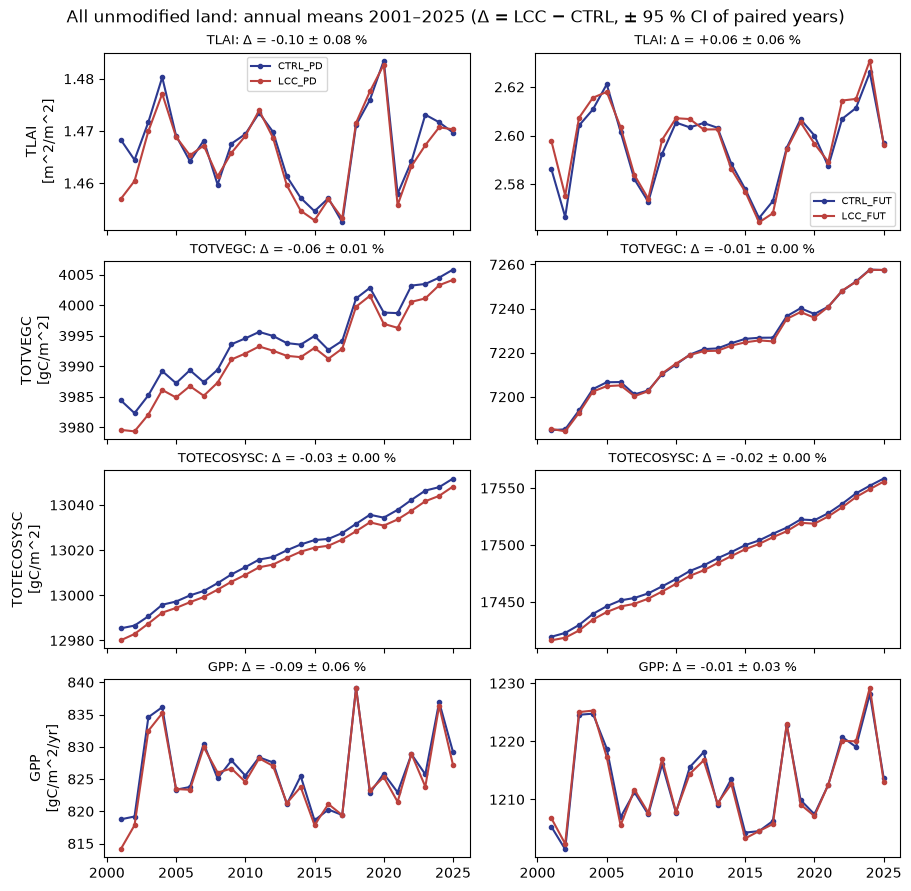

In [5]:
fig, axes = plt.subplots(len(VARS), 2, figsize=(9, 2.2 * len(VARS)), sharex=True, layout='constrained')
for j, period in enumerate(['PD', 'FUT']):
    for i, v in enumerate(VARS):
        ax = axes[i, j]
        c, l = SERIES[period, 2025, 'all unmodified land', v]
        ax.plot(c.year, c, 'o-', ms=3, color=COLOR['CTRL'], label=f'CTRL_{period}')
        ax.plot(l.year, l, 'o-', ms=3, color=COLOR['LCC'], label=f'LCC_{period}')
        r = table_A.loc[(period, '2001–2025', 'all unmodified land', v)]
        ax.set_title(f'{v}: Δ = {r.delta_pct:+.2f} ± {r.ci95_pct:.2f} %', fontsize=9)
        if j == 0:
            ax.set_ylabel(f"{v}\n[{r.units}]")
    axes[0, j].legend(fontsize=7)
fig.suptitle('All unmodified land: annual means 2001–2025 (Δ = LCC − CTRL, ± 95 % CI of paired years)')
fig.savefig(OUT / 'A_unmodified_land_timeseries.png', dpi=150)
plt.show()

## B. Cell by cell, unmodified land

Paired t-test of the 25 yearly differences in each cell; share of the unmodified land **area** with p < 0.05 (≈ 5 % expected by chance if the members are in the same state), and with p < 0.05 and Δ > 0.

In [6]:
import warnings
rows = []
for period in ['PD', 'FUT']:
    c_ann, l_ann = ANN[f'CTRL_{period}'], ANN[f'LCC_{period}']
    for v in VARS:
        d = (l_ann[v] - c_ann[v])
        with warnings.catch_warnings(), np.errstate(all='ignore'):
            warnings.simplefilter('ignore')
            p = xr.DataArray(stats.ttest_1samp(d.values, 0, axis=0).pvalue, coords=ref.area.coords)
        for region in ['all unmodified land', 'modified cells']:
            w = W.where(REGIONS[region] & np.isfinite(p))
            rows.append(dict(period=period, variable=v, region=region,
                             sig_area_frac=float(w.where(p < ALPHA).sum() / w.sum()),
                             sig_positive_frac=float(w.where((p < ALPHA) & (d.mean('year') > 0)).sum() / w.sum())))
table_B = pd.DataFrame(rows).set_index(['period', 'region', 'variable'])
table_B.to_csv(OUT / 'B_cellwise_significant_area.csv')
display(table_B.round(3))

sig_area_frac  sig_positive_frac
period region              variable                                    
PD     all unmodified land TLAI                0.230              0.113
       modified cells      TLAI                0.850              0.341
       all unmodified land TOTVEGC             0.629              0.292
       modified cells      TOTVEGC             0.968              0.608
       all unmodified land TOTECOSYSC          0.870              0.437
       modified cells      TOTECOSYSC          0.989              0.459
       all unmodified land GPP                 0.154              0.072
       modified cells      GPP                 0.801              0.290
FUT    all unmodified land TLAI                0.231              0.123
       modified cells      TLAI                0.917              0.268
       all unmodified land TOTVEGC             0.656              0.309
       modified cells      TOTVEGC             0.967              0.620
       all unmodified land TOTECOSYSC          0.884              0.405
       modified cells      TOTECOSYSC          0.987              0.433
       all unmodified land GPP                 0.149              0.069
       modified cells      GPP                 0.896              0.269

## Reading (2026-11-19)

**Cross-check (a):** processed files give exactly the raw-file FUT 2001–2014 numbers (max relative difference of the means 1.7e-16).

**All unmodified land, LCC − CTRL, 2001–2025, mean ± 95 % CI of 25 paired years (a):**

| | TLAI | TOTVEGC | TOTECOSYSC | GPP |
|---|---|---|---|---|
| PD | −0.10 ± 0.08 % | −0.06 ± 0.01 % | −0.03 ± 0.002 % | −0.10 ± 0.06 % |
| FUT | +0.06 ± 0.07 % | −0.01 ± 0.004 % | −0.02 ± 0.002 % | −0.01 ± 0.03 % |

Drift of TOTVEGC (both members alike): PD +0.21/+0.23 % per decade (CTRL/LCC), FUT +0.39/+0.39 % per decade (a).

**What it means.** Outside the modified cells the two members differ by ≤ 0.1 % in every variable, in both periods: at least 40× smaller than the change inside the modified cells (TOTVEGC +3.9 % PD, +4.7 % FUT; TLAI −3.9 / −6.3 %) (a). The carbon pools are nevertheless **significant** almost everywhere (paired p < 0.05 on 63–66 % of the unmodified area for TOTVEGC, 87–88 % for TOTECOSYSC, vs ≈ 5 % by chance) because nudging makes the yearly differences tiny and very stable (a). Slow pools carry a small systematic offset of a few hundredths of a percent; both members drift at the same rate, so it is an offset, not a divergence (b). As the Methods outline says: quote sizes, not p-values, for carbon pools. TLAI and GPP are significant on 15–23 % of the unmodified area (a).